# VPIN BTCUSDT Combined Research Notebook

Clean VPIN-focused notebook combining grid search and publication-style plots.

## Included
- Memory-safe monthly bucket construction
- VPIN grid search
- Signal metrics: IC, RankIC, top-5% return, crash probability, crash lift
- Classification metrics: precision, recall, F1
- Publication plots: price+VPIN overlay, bucket duration, time-aligned event study, return distribution, crash lift, monthly stability, spike zooms


In [1]:
import os, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 240)

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('./outputs')
CACHE_DIR = OUTPUT_DIR / 'cache'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIG_DIR = OUTPUT_DIR / 'figures'
REPORT_FIG_DIR = FIG_DIR / 'publication'
for d in [OUTPUT_DIR, CACHE_DIR, TABLE_DIR, FIG_DIR, REPORT_FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)


## 1. Configuration
Default is a 6-month validation window. `BASE_BUCKET_VOL=25` is memory safer; switch to `10.0` if your machine can handle it.


In [2]:
MONTH_FILES = [
    'BTCUSDT-aggTrades-2025-05.csv',
    'BTCUSDT-aggTrades-2025-06.csv',
    'BTCUSDT-aggTrades-2025-07.csv',
    'BTCUSDT-aggTrades-2025-08.csv',
    'BTCUSDT-aggTrades-2025-09.csv',
    'BTCUSDT-aggTrades-2025-10.csv',
]
BUCKET_BASIS = 'base'
BASE_BUCKET_VOL = 25.0
V_GRID = [25.0, 50.0, 100.0, 200.0]
N_GRID = [50, 75, 100]
HORIZONS_MIN = [15, 30, 60]
CRASH_THRESHOLDS = {15: -0.0070, 30: -0.0100, 60: -0.0150}
PCTL_GRID = [0.95, 0.975, 0.99]
Z_GRID = [1.5, 2.0, 2.5]
ABS_GRID = [0.6, 0.7, 0.8, 0.9]
EVENT_TIME_GRID_MIN = [1, 5, 10, 15, 30, 45, 60]
EVENT_SPIKE_QUANTILE = 0.95
label = '_'.join([f.replace('BTCUSDT-aggTrades-', '').replace('.csv', '') for f in MONTH_FILES])
label


'2025-05_2025-06_2025-07_2025-08_2025-09_2025-10'

## 2. Loader and bucket construction
Memory-safe workflow: raw monthly CSV → monthly base buckets → cached parquet → combined bucket table.


In [3]:
COLS = ['agg_trade_id','price','qty','first_id','last_id','timestamp','is_buyer_maker','is_best_match']

def load_one_month_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, header=None, names=COLS, usecols=['price','qty','timestamp','is_buyer_maker'],
                     dtype={'price':'float32','qty':'float32','timestamp':'Int64','is_buyer_maker':'str'})
    df['timestamp'] = pd.to_numeric(df['timestamp'], errors='coerce')
    df = df[df['timestamp'].notna() & (df['timestamp'] > 1_230_768_000_000_000) & (df['timestamp'] < 1_924_905_600_000_000)].copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'].astype(np.int64), unit='us', utc=True)
    df['is_buyer_maker'] = df['is_buyer_maker'].str.strip().str.lower() == 'true'
    df['price'] = pd.to_numeric(df['price'], errors='coerce')
    df['qty'] = pd.to_numeric(df['qty'], errors='coerce')
    return df.dropna().sort_values('timestamp').reset_index(drop=True)

def build_base_buckets(df: pd.DataFrame, base_bucket_vol: float, basis: str = 'base'):
    x = df.copy()
    is_buy_aggr = ~x['is_buyer_maker']
    if basis == 'base':
        x['bucket_qty'] = x['qty'].astype('float64')
    elif basis == 'quote':
        x['bucket_qty'] = x['price'].astype('float64') * x['qty'].astype('float64')
    else:
        raise ValueError('basis must be base or quote')
    x['buy_flow'] = np.where(is_buy_aggr, x['bucket_qty'], 0.0)
    x['sell_flow'] = np.where(~is_buy_aggr, x['bucket_qty'], 0.0)
    x['cum_flow'] = x['bucket_qty'].cumsum()
    x['bucket_id'] = np.floor(x['cum_flow'] / base_bucket_vol).astype(np.int64)
    buckets = x.groupby('bucket_id', sort=True).agg(
        start_time=('timestamp','first'), end_time=('timestamp','last'), end_price=('price','last'),
        total_flow=('bucket_qty','sum'), buy_flow=('buy_flow','sum'), sell_flow=('sell_flow','sum')
    ).reset_index(drop=True)
    n_days = max((buckets['end_time'].max() - buckets['start_time'].min()).days, 1)
    adv = buckets['total_flow'].sum() / n_days
    return buckets, adv

def build_or_load_monthly_base_buckets(fname):
    month_str = fname.replace('BTCUSDT-aggTrades-', '').replace('.csv', '')
    cache_path = CACHE_DIR / f'base_buckets_{month_str}_{BUCKET_BASIS}_basevol{int(BASE_BUCKET_VOL)}.parquet'
    if cache_path.exists():
        print('loading cached:', cache_path)
        return pd.read_parquet(cache_path)
    print('building:', fname)
    df_m = load_one_month_csv(DATA_DIR / fname)
    bb_m, adv_m = build_base_buckets(df_m, BASE_BUCKET_VOL, BUCKET_BASIS)
    del df_m
    gc.collect()
    bb_m.to_parquet(cache_path, index=False)
    print('saved:', cache_path, '| buckets:', f'{len(bb_m):,}', '| ADV:', round(float(adv_m), 2))
    return bb_m


In [4]:
monthly_buckets = [build_or_load_monthly_base_buckets(fname) for fname in MONTH_FILES]
base_buckets = pd.concat(monthly_buckets, ignore_index=True).sort_values('end_time').reset_index(drop=True)
del monthly_buckets
gc.collect()
combined_cache_path = CACHE_DIR / f'base_buckets_combined_{label}_{BUCKET_BASIS}_basevol{int(BASE_BUCKET_VOL)}.parquet'
base_buckets.to_parquet(combined_cache_path, index=False)
print('combined base buckets:', f'{len(base_buckets):,}')
print(base_buckets['start_time'].min(), '->', base_buckets['end_time'].max())
base_buckets.head()


building: BTCUSDT-aggTrades-2025-05.csv
saved: outputs\cache\base_buckets_2025-05_base_basevol25.parquet | buckets: 25,682 | ADV: 21407.22
building: BTCUSDT-aggTrades-2025-06.csv
saved: outputs\cache\base_buckets_2025-06_base_basevol25.parquet | buckets: 17,098 | ADV: 14742.98
building: BTCUSDT-aggTrades-2025-07.csv
saved: outputs\cache\base_buckets_2025-07_base_basevol25.parquet | buckets: 19,372 | ADV: 16143.86
building: BTCUSDT-aggTrades-2025-08.csv
saved: outputs\cache\base_buckets_2025-08_base_basevol25.parquet | buckets: 18,851 | ADV: 15712.23
building: BTCUSDT-aggTrades-2025-09.csv
saved: outputs\cache\base_buckets_2025-09_base_basevol25.parquet | buckets: 14,982 | ADV: 12915.59
building: BTCUSDT-aggTrades-2025-10.csv
saved: outputs\cache\base_buckets_2025-10_base_basevol25.parquet | buckets: 28,811 | ADV: 24010.01
combined base buckets: 124,796
2025-05-01 00:00:00.079126+00:00 -> 2025-10-31 23:59:59.599399+00:00


,start_time,end_time,end_price,total_flow,buy_flow,sell_flow
0,2025-05-01 00:00:00.079126+00:00,2025-05-01 00:05:10.870922+00:00,94253.34375,24.72476,14.68763,10.03713
1,2025-05-01 00:05:11.586288+00:00,2025-05-01 00:07:14.130440+00:00,94216.03125,25.06364,13.14352,11.92012
2,2025-05-01 00:07:14.144785+00:00,2025-05-01 00:10:36.683199+00:00,94312.28125,25.21050,17.78896,7.42154
3,2025-05-01 00:10:36.683199+00:00,2025-05-01 00:12:25.536770+00:00,94333.25000,24.94596,16.90932,8.03664
4,2025-05-01 00:12:25.643891+00:00,2025-05-01 00:16:18.286884+00:00,94314.03125,24.70992,9.22714,15.48278


## 3. VPIN and evaluation helpers


In [5]:
def aggregate_base_buckets_to_V(base_buckets: pd.DataFrame, target_V: float, base_V: float):
    ratio = int(round(target_V / base_V))
    if target_V < base_V or not np.isclose(ratio * base_V, target_V):
        raise ValueError(f'target_V={target_V} must be an integer multiple of base_V={base_V}')
    x = base_buckets.copy()
    x['agg_id'] = np.arange(len(x)) // ratio
    agg = x.groupby('agg_id', sort=True).agg(
        start_time=('start_time','first'), end_time=('end_time','last'), end_price=('end_price','last'),
        total_flow=('total_flow','sum'), buy_flow=('buy_flow','sum'), sell_flow=('sell_flow','sum')
    ).reset_index(drop=True)
    agg['V'] = target_V
    agg['bucket_imbalance'] = (agg['buy_flow'] - agg['sell_flow']).abs() / target_V
    return agg

def add_forward_returns_by_time(buckets: pd.DataFrame, horizons_min):
    x = buckets.copy()
    end_ns = x['end_time'].astype('int64').to_numpy()
    price = x['end_price'].astype('float64').to_numpy()
    for h in horizons_min:
        target_ns = (x['end_time'] + pd.Timedelta(minutes=h)).astype('int64').to_numpy()
        idx = np.searchsorted(end_ns, target_ns, side='left')
        fwd_price = np.full(len(x), np.nan, dtype=np.float64)
        valid = idx < len(x)
        fwd_price[valid] = price[idx[valid]]
        x[f'fwd_ret_{h}m'] = np.log(fwd_price / price)
        x[f'crash_{h}m'] = (x[f'fwd_ret_{h}m'] <= CRASH_THRESHOLDS[h]).astype(int)
    return x

def compute_signal_metrics(df, vpin_col, ret_col, crash_col):
    z = df[[vpin_col, ret_col, crash_col]].dropna().copy()
    if len(z) < 20:
        return None
    q95, q99 = z[vpin_col].quantile(0.95), z[vpin_col].quantile(0.99)
    top5, top1 = z[z[vpin_col] >= q95], z[z[vpin_col] >= q99]
    p_all = z[crash_col].mean()
    p_top5 = top5[crash_col].mean() if len(top5) else np.nan
    p_top1 = top1[crash_col].mean() if len(top1) else np.nan
    return {
        'n_obs': len(z), 'ic': z[vpin_col].corr(z[ret_col], method='pearson'),
        'rank_ic': z[vpin_col].corr(z[ret_col], method='spearman'),
        'mean_ret_all': z[ret_col].mean(),
        'mean_ret_top5pct_vpin': top5[ret_col].mean() if len(top5) else np.nan,
        'mean_ret_top1pct_vpin': top1[ret_col].mean() if len(top1) else np.nan,
        'p_crash_all': p_all, 'p_crash_top5pct_vpin': p_top5, 'p_crash_top1pct_vpin': p_top1,
        'crash_lift_top5': (p_top5 / p_all) if pd.notna(p_top5) and p_all > 0 else np.nan,
        'crash_lift_top1': (p_top1 / p_all) if pd.notna(p_top1) and p_all > 0 else np.nan
    }

def classification_scores(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else np.nan
    return {'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn, 'precision': precision, 'recall': recall, 'f1': f1}

def add_alerts(df, vpin_col, mode, level):
    x, s = df.copy(), df[vpin_col]
    if mode == 'abs':
        x['alert'] = (s >= level).astype(int)
    elif mode == 'pct':
        x['alert'] = (s >= s.quantile(level)).astype(int)
    elif mode == 'z':
        sig = s.std(ddof=0)
        z = (s - s.mean()) / sig if sig > 0 else pd.Series(np.nan, index=s.index)
        x['alert'] = (z >= level).astype(int)
    else:
        raise ValueError('mode must be abs, pct, or z')
    return x


## 4. Grid search


In [6]:
signal_rows, class_rows = [], []
for V in V_GRID:
    print('V =', V)
    buckets_V = aggregate_base_buckets_to_V(base_buckets, V, BASE_BUCKET_VOL)
    buckets_V = add_forward_returns_by_time(buckets_V, HORIZONS_MIN)
    for n in N_GRID:
        x = buckets_V.copy()
        x['vpin'] = x['bucket_imbalance'].rolling(n, min_periods=n).mean()
        for h in HORIZONS_MIN:
            ret_col, crash_col = f'fwd_ret_{h}m', f'crash_{h}m'
            sig = compute_signal_metrics(x, 'vpin', ret_col, crash_col)
            if sig is not None:
                sig.update({'V': V, 'n': n, 'horizon_min': h, 'months': label, 'base_bucket_vol': BASE_BUCKET_VOL})
                signal_rows.append(sig)
            for mode, grid in [('abs', ABS_GRID), ('pct', PCTL_GRID), ('z', Z_GRID)]:
                for level in grid:
                    y = add_alerts(x, 'vpin', mode, level)
                    z = y.dropna(subset=['alert', crash_col]).copy()
                    if len(z) < 20:
                        continue
                    scores = classification_scores(z[crash_col], z['alert'])
                    scores.update({'V': V, 'n': n, 'horizon_min': h, 'rule_type': mode, 'rule_level': level, 'crash_threshold': CRASH_THRESHOLDS[h], 'months': label, 'base_bucket_vol': BASE_BUCKET_VOL})
                    class_rows.append(scores)
signal_df, class_df = pd.DataFrame(signal_rows), pd.DataFrame(class_rows)
print('signal_df:', signal_df.shape)
print('class_df:', class_df.shape)


V = 25.0
V = 50.0
V = 100.0
V = 200.0
signal_df: (36, 16)
class_df: (360, 15)


In [7]:
signal_out = TABLE_DIR / f'signal_metrics_combined_{label}_{BUCKET_BASIS}_basevol{int(BASE_BUCKET_VOL)}.csv'
class_out = TABLE_DIR / f'classification_metrics_combined_{label}_{BUCKET_BASIS}_basevol{int(BASE_BUCKET_VOL)}.csv'
signal_df.to_csv(signal_out, index=False)
class_df.to_csv(class_out, index=False)
signal_ranked = signal_df.sort_values(['mean_ret_top5pct_vpin','ic','crash_lift_top5'], ascending=[True, True, False]).reset_index(drop=True)
class_ranked = class_df.sort_values(['f1','precision','recall'], ascending=[False, False, False]).reset_index(drop=True)
display(signal_ranked.head(30))
display(class_ranked.head(30))


,n_obs,ic,rank_ic,mean_ret_all,mean_ret_top5pct_vpin,mean_ret_top1pct_vpin,p_crash_all,p_crash_top5pct_vpin,p_crash_top1pct_vpin,crash_lift_top5,crash_lift_top1,V,n,horizon_min,months,base_bucket_vol
0,62294,-0.073030,-0.019983,0.000221,-0.001101,-0.000604,0.007930,0.026645,0.000000,3.360000,0.000000,50.0,100,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
1,62319,-0.062445,-0.005761,0.000221,-0.001077,-0.000952,0.007927,0.024711,0.000000,3.117359,0.000000,50.0,75,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
2,31097,-0.045941,-0.013241,0.000227,-0.000884,-0.000630,0.008007,0.023151,0.035370,2.891287,4.417245,100.0,100,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
3,62296,-0.063611,-0.023088,0.000109,-0.000783,-0.000705,0.012441,0.026645,0.000000,2.141798,0.000000,50.0,100,30,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
4,15524,-0.027551,0.000721,0.000209,-0.000769,-0.000423,0.008439,0.027027,0.000000,3.202806,0.000000,200.0,75,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
5,62321,-0.050445,-0.008119,0.000109,-0.000640,-0.001096,0.012436,0.024062,0.000000,1.934894,0.000000,50.0,75,30,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
6,15549,-0.033181,0.001803,0.000216,-0.000588,-0.000559,0.008425,0.015424,0.006410,1.830766,0.760863,200.0,50,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
7,124688,-0.070058,-0.004522,0.000224,-0.000545,-0.000786,0.007836,0.008340,0.000000,1.064381,0.000000,25.0,100,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
8,31148,-0.062107,-0.031255,0.000110,-0.000489,-0.000889,0.012328,0.013479,0.003205,1.093329,0.259983,100.0,50,30,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
9,31147,-0.066303,-0.028599,0.000229,-0.000489,-0.000688,0.007994,0.008344,0.000000,1.043741,0.000000,100.0,50,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0


,tp,fp,fn,tn,precision,recall,f1,V,n,horizon_min,rule_type,rule_level,crash_threshold,months,base_bucket_vol
0,22,472,227,30478,0.044534,0.088353,0.059219,100.0,100,60,z,2.500,-0.015,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
1,25,751,220,14604,0.032216,0.102041,0.048972,200.0,100,15,pct,0.950,-0.007,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
2,57,1501,718,60122,0.036585,0.073548,0.048864,50.0,100,30,pct,0.975,-0.010,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
3,15,493,116,14976,0.029528,0.114504,0.046948,200.0,75,60,z,2.000,-0.015,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
4,24,754,225,30196,0.030848,0.096386,0.046738,100.0,100,60,pct,0.975,-0.015,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
5,21,756,110,14713,0.027027,0.160305,0.046256,200.0,75,60,pct,0.950,-0.015,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
6,83,3032,411,58872,0.026645,0.168016,0.045996,50.0,100,60,pct,0.950,-0.015,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
7,64,1959,711,59664,0.031636,0.082581,0.045747,50.0,100,30,z,2.000,-0.010,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
8,104,4094,390,57810,0.024774,0.210526,0.044331,50.0,100,60,z,1.500,-0.015,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0
9,20,756,111,14713,0.025773,0.152672,0.044101,200.0,100,60,pct,0.950,-0.015,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0


## 5. Best result by horizon and chosen publication parameter


In [8]:
best_signal_by_h = signal_ranked.groupby('horizon_min', as_index=False).first()[['horizon_min','V','n','ic','rank_ic','mean_ret_top5pct_vpin','mean_ret_top1pct_vpin','p_crash_all','p_crash_top5pct_vpin','crash_lift_top5']].sort_values('horizon_min')
best_class_by_h = class_ranked.groupby('horizon_min', as_index=False).first()[['horizon_min','V','n','rule_type','rule_level','precision','recall','f1']].sort_values('horizon_min')
display(best_signal_by_h)
display(best_class_by_h)
best_signal_by_h.to_csv(TABLE_DIR / f'best_signal_by_h_combined_{label}_{BUCKET_BASIS}.csv', index=False)
best_class_by_h.to_csv(TABLE_DIR / f'best_class_by_h_combined_{label}_{BUCKET_BASIS}.csv', index=False)
best = signal_ranked.iloc[0]
BEST_V, BEST_N = float(best['V']), int(best['n'])
print('Selected publication parameter:')
display(best.to_frame().T)


,horizon_min,V,n,ic,rank_ic,mean_ret_top5pct_vpin,mean_ret_top1pct_vpin,p_crash_all,p_crash_top5pct_vpin,crash_lift_top5
0,15,50.0,100,-0.051673,-0.013158,-0.000360,-0.000507,0.013981,0.018299,1.308777
1,30,50.0,100,-0.063611,-0.023088,-0.000783,-0.000705,0.012441,0.026645,2.141798
2,60,50.0,100,-0.073030,-0.019983,-0.001101,-0.000604,0.007930,0.026645,3.360000


,horizon_min,V,n,rule_type,rule_level,precision,recall,f1
0,15,200.0,100,pct,0.950,0.032216,0.102041,0.048972
1,30,50.0,100,pct,0.975,0.036585,0.073548,0.048864
2,60,100.0,100,z,2.500,0.044534,0.088353,0.059219


Selected publication parameter:


,n_obs,ic,rank_ic,mean_ret_all,mean_ret_top5pct_vpin,mean_ret_top1pct_vpin,p_crash_all,p_crash_top5pct_vpin,p_crash_top1pct_vpin,crash_lift_top5,crash_lift_top1,V,n,horizon_min,months,base_bucket_vol
0,62294,-0.07303,-0.019983,0.000221,-0.001101,-0.000604,0.00793,0.026645,0.0,3.36,0.0,50.0,100,60,2025-05_2025-06_2025-07_2025-08_2025-09_2025-10,25.0


## 6. Build selected VPIN series for publication plots


In [9]:
vpin_df = aggregate_base_buckets_to_V(base_buckets, BEST_V, BASE_BUCKET_VOL)
vpin_df['vpin'] = vpin_df['bucket_imbalance'].rolling(BEST_N, min_periods=BEST_N).mean()
vpin_df = add_forward_returns_by_time(vpin_df, HORIZONS_MIN)
vpin_df['bucket_duration_min'] = (vpin_df['end_time'] - vpin_df['start_time']).dt.total_seconds() / 60.0
vpin_cutoff = vpin_df['vpin'].quantile(EVENT_SPIKE_QUANTILE)
vpin_df['vpin_spike'] = vpin_df['vpin'] >= vpin_cutoff
print('VPIN cutoff:', vpin_cutoff)
print('spike count:', int(vpin_df['vpin_spike'].sum()))
vpin_df.head()


VPIN cutoff: 0.38061123794172136
spike count: 3115


,start_time,end_time,end_price,total_flow,buy_flow,sell_flow,V,bucket_imbalance,vpin,fwd_ret_15m,crash_15m,fwd_ret_30m,crash_30m,fwd_ret_60m,crash_60m,bucket_duration_min,vpin_spike
0,2025-05-01 00:00:00.079126+00:00,2025-05-01 00:07:14.130440+00:00,94216.031250,49.788400,27.831150,21.95725,50.0,0.117478,NaN,0.000296,0,0.001614,0,0.003822,0,7.234189,False
1,2025-05-01 00:07:14.144785+00:00,2025-05-01 00:12:25.536770+00:00,94333.250000,50.156459,34.698279,15.45818,50.0,0.384802,NaN,-0.000947,0,0.000371,0,0.002924,0,5.189866,False
2,2025-05-01 00:12:25.643891+00:00,2025-05-01 00:21:32.044173+00:00,94187.867188,49.526310,17.107870,32.41844,50.0,0.306211,NaN,0.001913,0,0.001704,0,0.005047,0,9.106671,False
3,2025-05-01 00:21:32.044173+00:00,2025-05-01 00:31:29.780953+00:00,94243.929688,47.258410,27.523480,19.73493,50.0,0.155771,NaN,0.001318,0,0.002425,0,0.004713,0,9.962280,False
4,2025-05-01 00:31:29.813390+00:00,2025-05-01 00:48:00.427413+00:00,94368.218750,53.005850,23.641860,29.36399,50.0,0.114443,NaN,0.001107,0,0.003151,0,0.003088,0,16.510234,False


# Publication plots


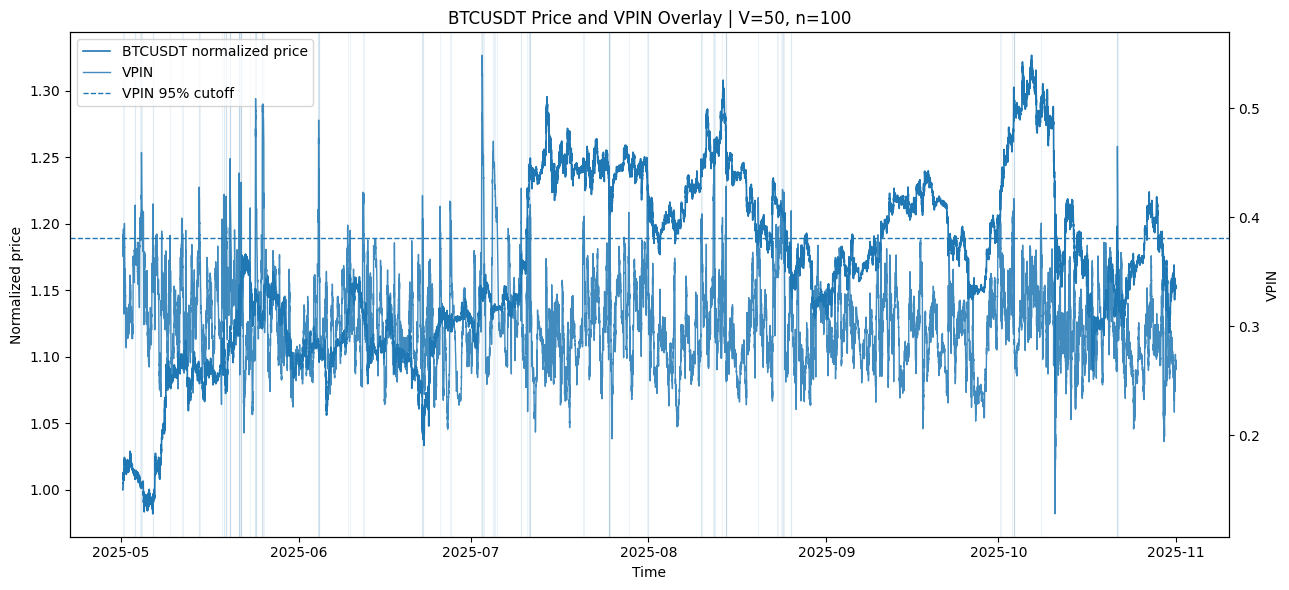

saved: outputs\figures\publication\fig1_price_vpin_overlay_V50_n100.png


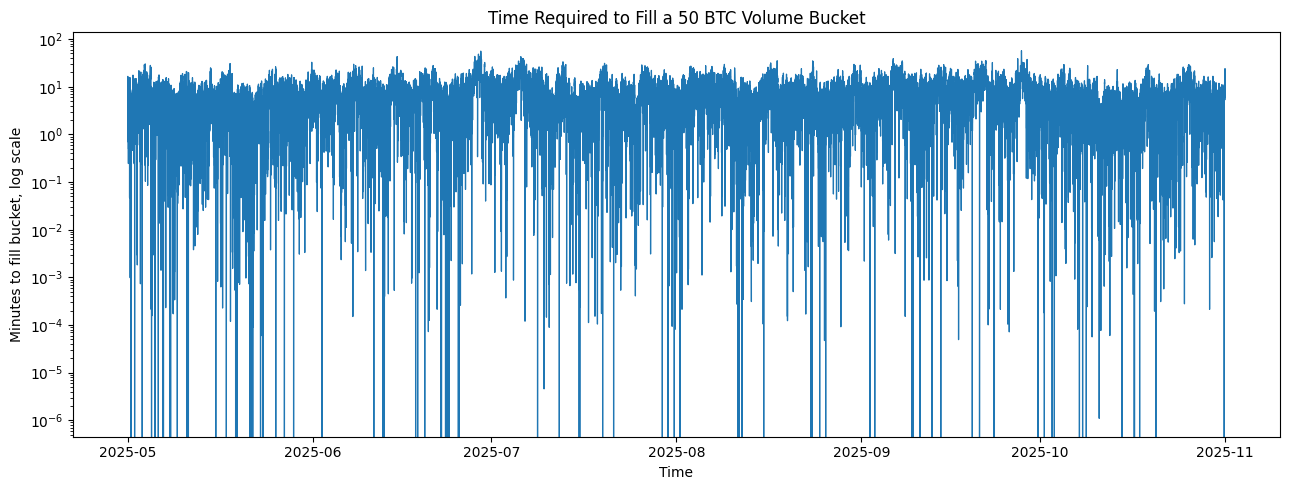

saved: outputs\figures\publication\fig2_bucket_duration_V50.png


In [10]:
def plot_price_vpin_overlay(vpin_df, vpin_cutoff):
    x = vpin_df.dropna(subset=['vpin']).copy()
    x['price_norm'] = x['end_price'] / x['end_price'].iloc[0]
    fig, ax1 = plt.subplots(figsize=(13, 6))
    ax1.plot(x['end_time'], x['price_norm'], linewidth=1.2, label='BTCUSDT normalized price')
    ax1.set_xlabel('Time'); ax1.set_ylabel('Normalized price')
    ax2 = ax1.twinx()
    ax2.plot(x['end_time'], x['vpin'], linewidth=1.0, alpha=0.85, label='VPIN')
    ax2.axhline(vpin_cutoff, linestyle='--', linewidth=1.0, label=f'VPIN {int(EVENT_SPIKE_QUANTILE*100)}% cutoff')
    ax2.set_ylabel('VPIN')
    spike_times = x.loc[x['vpin_spike'], 'end_time']
    step = max(1, len(spike_times)//120)
    for t in spike_times.iloc[::step]: ax1.axvline(t, alpha=0.08, linewidth=0.8)
    lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
    plt.title(f'BTCUSDT Price and VPIN Overlay | V={int(BEST_V)}, n={BEST_N}')
    fig.tight_layout()
    out = REPORT_FIG_DIR / f'fig1_price_vpin_overlay_V{int(BEST_V)}_n{BEST_N}.png'
    plt.savefig(out, dpi=180); plt.show(); print('saved:', out)

def plot_bucket_duration(vpin_df):
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(vpin_df['end_time'], vpin_df['bucket_duration_min'], linewidth=0.9)
    ax.set_yscale('log'); ax.set_xlabel('Time'); ax.set_ylabel('Minutes to fill bucket, log scale')
    ax.set_title(f'Time Required to Fill a {int(BEST_V)} BTC Volume Bucket')
    fig.tight_layout()
    out = REPORT_FIG_DIR / f'fig2_bucket_duration_V{int(BEST_V)}.png'
    plt.savefig(out, dpi=180); plt.show(); print('saved:', out)

plot_price_vpin_overlay(vpin_df, vpin_cutoff)
plot_bucket_duration(vpin_df)


,minutes_after_spike,mean_return,median_return,p25_return,p75_return,p10_return,p90_return,n_events
0,1,-0.000027,-0.000016,-0.000655,0.000643,-0.001316,0.001376,3115
1,5,-0.000113,-0.000082,-0.001012,0.000889,-0.002136,0.001868,3115
2,10,-0.000220,-0.000172,-0.001333,0.000988,-0.002848,0.002485,3115
3,15,-0.000360,-0.000272,-0.001580,0.001063,-0.003302,0.002752,3115
4,30,-0.000783,-0.000474,-0.002419,0.001280,-0.005135,0.003445,3115
5,45,-0.000968,-0.000560,-0.002791,0.001462,-0.005704,0.003787,3115
6,60,-0.001101,-0.000452,-0.003156,0.001650,-0.006599,0.003927,3115


saved: outputs\tables\publication_event_study_combined_2025-05_2025-06_2025-07_2025-08_2025-09_2025-10_V50_n100.csv


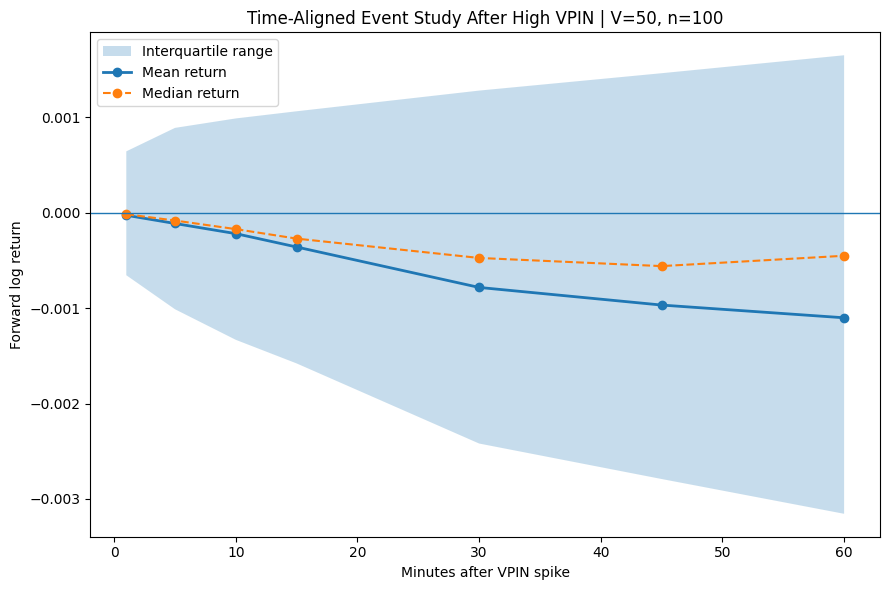

saved: outputs\figures\publication\fig3_time_aligned_event_study_V50_n100.png


In [11]:
def time_aligned_event_study(df, time_grid_min):
    x = df.dropna(subset=['vpin']).copy()
    times = x['end_time'].astype('int64').to_numpy(); prices = x['end_price'].astype('float64').to_numpy()
    spike_idx = np.where(x['vpin_spike'].to_numpy())[0]
    paths = []
    for i in spike_idx:
        t0, p0 = times[i], prices[i]
        row = []
        for m in time_grid_min:
            j = np.searchsorted(times, t0 + pd.Timedelta(minutes=m).value, side='left')
            row.append(np.log(prices[j] / p0) if j < len(times) else np.nan)
        paths.append(row)
    arr = np.array(paths, dtype=float)
    out = pd.DataFrame({'minutes_after_spike': time_grid_min, 'mean_return': np.nanmean(arr, axis=0), 'median_return': np.nanmedian(arr, axis=0), 'p25_return': np.nanpercentile(arr, 25, axis=0), 'p75_return': np.nanpercentile(arr, 75, axis=0), 'p10_return': np.nanpercentile(arr, 10, axis=0), 'p90_return': np.nanpercentile(arr, 90, axis=0), 'n_events': np.sum(~np.isnan(arr), axis=0)})
    return out, arr

event_df, event_paths = time_aligned_event_study(vpin_df, EVENT_TIME_GRID_MIN)
display(event_df)
event_out = TABLE_DIR / f'publication_event_study_combined_{label}_V{int(BEST_V)}_n{BEST_N}.csv'
event_df.to_csv(event_out, index=False)
print('saved:', event_out)

fig, ax = plt.subplots(figsize=(9, 6))
x = event_df['minutes_after_spike'].to_numpy()
ax.fill_between(x, event_df['p25_return'], event_df['p75_return'], alpha=0.25, label='Interquartile range')
ax.plot(x, event_df['mean_return'], marker='o', linewidth=2.0, label='Mean return')
ax.plot(x, event_df['median_return'], marker='o', linewidth=1.5, linestyle='--', label='Median return')
ax.axhline(0.0, linewidth=1.0)
ax.set_xlabel('Minutes after VPIN spike'); ax.set_ylabel('Forward log return')
ax.set_title(f'Time-Aligned Event Study After High VPIN | V={int(BEST_V)}, n={BEST_N}')
ax.legend(); fig.tight_layout()
out = REPORT_FIG_DIR / f'fig3_time_aligned_event_study_V{int(BEST_V)}_n{BEST_N}.png'
plt.savefig(out, dpi=180); plt.show(); print('saved:', out)


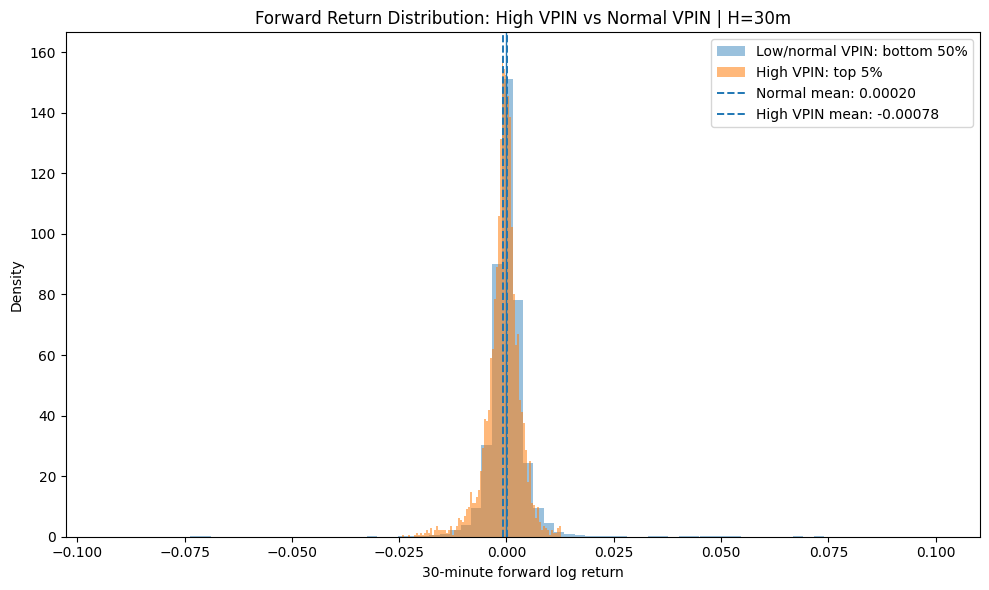

saved: outputs\figures\publication\fig4_return_distribution_high_vs_low_vpin_H30m_V50_n100.png


In [12]:
def plot_high_low_vpin_return_distribution(vpin_df, horizon_min=30):
    ret_col = f'fwd_ret_{horizon_min}m'
    x = vpin_df.dropna(subset=['vpin', ret_col]).copy()
    high = x.loc[x['vpin'] >= x['vpin'].quantile(0.95), ret_col]
    normal = x.loc[x['vpin'] <= x['vpin'].quantile(0.50), ret_col]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(normal, bins=80, alpha=0.45, density=True, label='Low/normal VPIN: bottom 50%')
    ax.hist(high, bins=80, alpha=0.55, density=True, label='High VPIN: top 5%')
    ax.axvline(normal.mean(), linewidth=1.4, linestyle='--', label=f'Normal mean: {normal.mean():.5f}')
    ax.axvline(high.mean(), linewidth=1.4, linestyle='--', label=f'High VPIN mean: {high.mean():.5f}')
    ax.axvline(0.0, linewidth=1.0)
    ax.set_xlabel(f'{horizon_min}-minute forward log return'); ax.set_ylabel('Density')
    ax.set_title(f'Forward Return Distribution: High VPIN vs Normal VPIN | H={horizon_min}m')
    ax.legend(); fig.tight_layout()
    out = REPORT_FIG_DIR / f'fig4_return_distribution_high_vs_low_vpin_H{horizon_min}m_V{int(BEST_V)}_n{BEST_N}.png'
    plt.savefig(out, dpi=180); plt.show(); print('saved:', out)

plot_high_low_vpin_return_distribution(vpin_df, 30)


,horizon_min,p_crash_all,p_crash_high_vpin,crash_lift,n_obs,n_high_vpin
0,15,0.013981,0.018299,1.308819,62299,3115
1,30,0.012440,0.026645,2.141901,62299,3115
2,60,0.007930,0.026645,3.360270,62299,3115


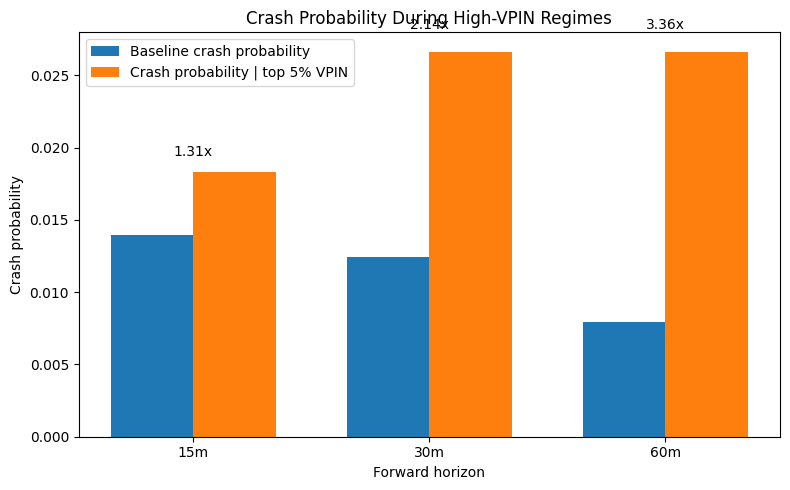

saved: outputs\figures\publication\fig5_crash_lift_V50_n100.png


In [13]:
def crash_lift_summary(vpin_df, horizons_min):
    x = vpin_df.dropna(subset=['vpin']).copy(); out = []
    for h in horizons_min:
        crash = x[f'fwd_ret_{h}m'] <= CRASH_THRESHOLDS[h]
        high = x['vpin'] >= x['vpin'].quantile(EVENT_SPIKE_QUANTILE)
        p_all, p_high = crash.mean(), crash[high].mean()
        out.append({'horizon_min': h, 'p_crash_all': p_all, 'p_crash_high_vpin': p_high, 'crash_lift': p_high / p_all if p_all > 0 else np.nan, 'n_obs': len(x), 'n_high_vpin': int(high.sum())})
    return pd.DataFrame(out)
crash_df = crash_lift_summary(vpin_df, HORIZONS_MIN)
display(crash_df)
crash_out = TABLE_DIR / f'publication_crash_lift_combined_{label}_V{int(BEST_V)}_n{BEST_N}.csv'
crash_df.to_csv(crash_out, index=False)
fig, ax = plt.subplots(figsize=(8, 5))
xx = np.arange(len(crash_df)); width = 0.35
ax.bar(xx - width/2, crash_df['p_crash_all'], width, label='Baseline crash probability')
ax.bar(xx + width/2, crash_df['p_crash_high_vpin'], width, label='Crash probability | top 5% VPIN')
ax.set_xticks(xx); ax.set_xticklabels([f'{int(h)}m' for h in crash_df['horizon_min']])
ax.set_xlabel('Forward horizon'); ax.set_ylabel('Crash probability'); ax.set_title('Crash Probability During High-VPIN Regimes'); ax.legend()
for i, lift in enumerate(crash_df['crash_lift']):
    ymax = max(crash_df.loc[i, 'p_crash_all'], crash_df.loc[i, 'p_crash_high_vpin'])
    ax.text(i, ymax * 1.05, f'{lift:.2f}x', ha='center', va='bottom')
fig.tight_layout(); out = REPORT_FIG_DIR / f'fig5_crash_lift_V{int(BEST_V)}_n{BEST_N}.png'
plt.savefig(out, dpi=180); plt.show(); print('saved:', out)


## 7. Month-by-month stability and spike windows


loading cached: outputs\cache\base_buckets_2025-05_base_basevol25.parquet
loading cached: outputs\cache\base_buckets_2025-06_base_basevol25.parquet
loading cached: outputs\cache\base_buckets_2025-07_base_basevol25.parquet
loading cached: outputs\cache\base_buckets_2025-08_base_basevol25.parquet
loading cached: outputs\cache\base_buckets_2025-09_base_basevol25.parquet
loading cached: outputs\cache\base_buckets_2025-10_base_basevol25.parquet


,n_obs,ic,rank_ic,mean_ret_all,mean_ret_top5pct_vpin,mean_ret_top1pct_vpin,p_crash_all,p_crash_top5pct_vpin,p_crash_top1pct_vpin,crash_lift_top5,crash_lift_top1,month,V,n,horizon_min
0,12740,-0.018259,-0.019465,0.000045,-0.000691,-0.000068,0.014521,0.026688,0.000000,1.837838,0.000000,2025-05,50.0,100,15
1,12739,-0.035603,-0.029064,0.000031,-0.001050,0.000265,0.014287,0.029827,0.000000,2.087748,0.000000,2025-05,50.0,100,30
2,12734,-0.025310,-0.002554,0.000154,-0.000586,0.000874,0.009345,0.025118,0.000000,2.687809,0.000000,2025-05,50.0,100,60
3,8447,-0.032017,-0.032495,-0.000022,-0.000206,-0.000937,0.013378,0.004728,0.000000,0.353438,0.000000,2025-06,50.0,100,15
4,8446,-0.055963,-0.048787,-0.000017,-0.000322,-0.001235,0.011485,0.004728,0.000000,0.411689,0.000000,2025-06,50.0,100,30
5,8445,-0.061648,-0.070677,-0.000045,-0.000423,-0.001124,0.008407,0.000000,0.000000,0.000000,0.000000,2025-06,50.0,100,60
6,9582,-0.007696,-0.000225,0.000108,-0.000646,0.000125,0.004488,0.002083,0.000000,0.464244,0.000000,2025-07,50.0,100,15
7,9571,-0.030324,-0.019409,0.000108,-0.001549,0.000153,0.003552,0.000000,0.000000,0.000000,0.000000,2025-07,50.0,100,30
8,9561,-0.056913,-0.029148,0.000055,-0.002310,0.000110,0.001569,0.000000,0.000000,0.000000,0.000000,2025-07,50.0,100,60
9,9323,-0.009128,0.021031,0.000099,-0.000404,-0.000984,0.007937,0.034261,0.095745,4.316453,12.062536,2025-08,50.0,100,15


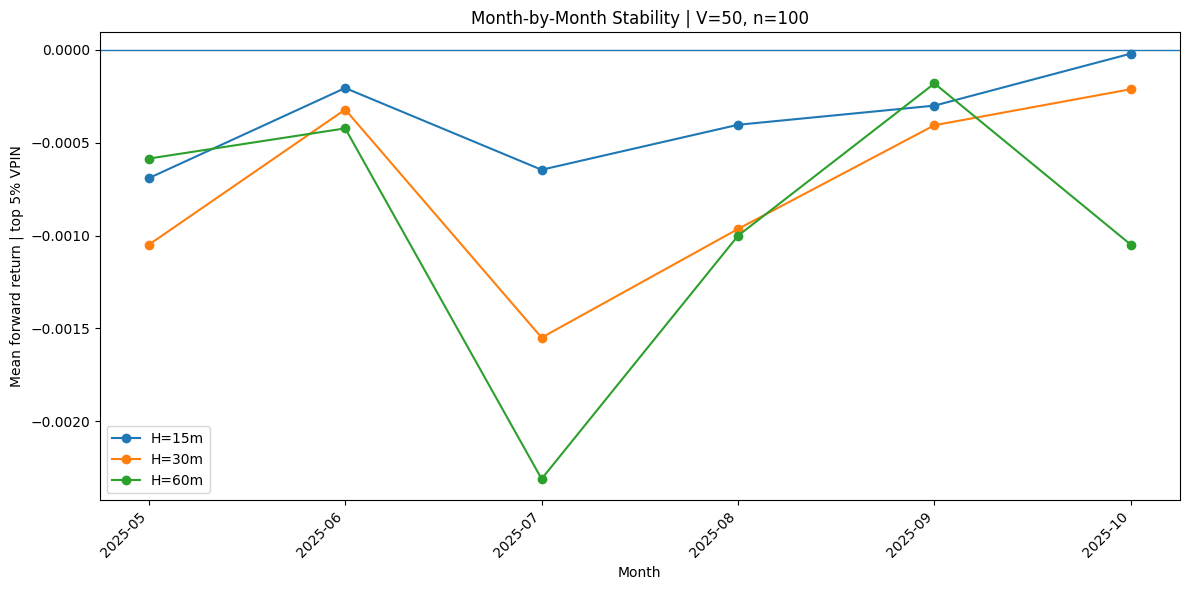

saved: outputs\figures\publication\fig6_monthly_stability_V50_n100.png


In [14]:
def compute_one_candidate_on_buckets(base_buckets_one, V, n, h, base_V):
    buckets_V = aggregate_base_buckets_to_V(base_buckets_one, V, base_V)
    buckets_V = add_forward_returns_by_time(buckets_V, [h])
    buckets_V['vpin'] = buckets_V['bucket_imbalance'].rolling(n, min_periods=n).mean()
    return compute_signal_metrics(buckets_V, 'vpin', f'fwd_ret_{h}m', f'crash_{h}m')
stability_rows = []
for fname in MONTH_FILES:
    month_str = fname.replace('BTCUSDT-aggTrades-', '').replace('.csv', '')
    bb_m = build_or_load_monthly_base_buckets(fname)
    for h in HORIZONS_MIN:
        sig = compute_one_candidate_on_buckets(bb_m, BEST_V, BEST_N, h, BASE_BUCKET_VOL)
        if sig is not None:
            sig.update({'month': month_str, 'V': BEST_V, 'n': BEST_N, 'horizon_min': h})
            stability_rows.append(sig)
stability_df = pd.DataFrame(stability_rows)
stability_out = TABLE_DIR / f'month_by_month_stability_combined_{label}_{BUCKET_BASIS}_V{int(BEST_V)}_n{BEST_N}.csv'
stability_df.to_csv(stability_out, index=False)
display(stability_df)
fig, ax = plt.subplots(figsize=(12, 6))
stability_df['candidate'] = 'H=' + stability_df['horizon_min'].astype(int).astype(str) + 'm'
for cand, g in stability_df.groupby('candidate'):
    g = g.sort_values('month')
    ax.plot(g['month'], g['mean_ret_top5pct_vpin'], marker='o', linewidth=1.5, label=cand)
ax.axhline(0.0, linewidth=1.0); ax.set_xlabel('Month'); ax.set_ylabel('Mean forward return | top 5% VPIN')
ax.set_title(f'Month-by-Month Stability | V={int(BEST_V)}, n={BEST_N}'); ax.legend(); fig.autofmt_xdate(rotation=45); fig.tight_layout()
out = REPORT_FIG_DIR / f'fig6_monthly_stability_V{int(BEST_V)}_n{BEST_N}.png'
plt.savefig(out, dpi=180); plt.show(); print('saved:', out)


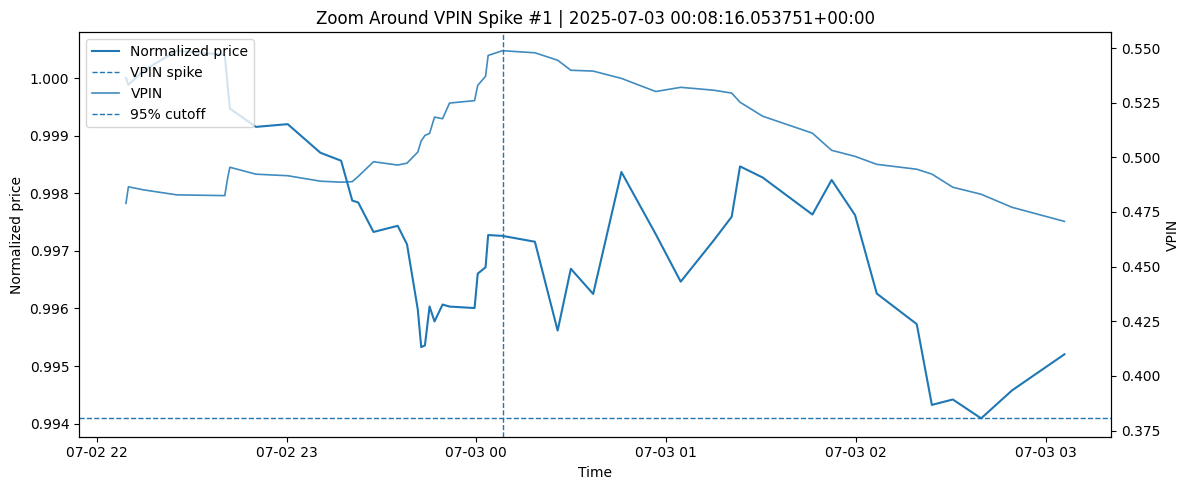

saved: outputs\figures\publication\fig7_spike_window_1_V50_n100.png


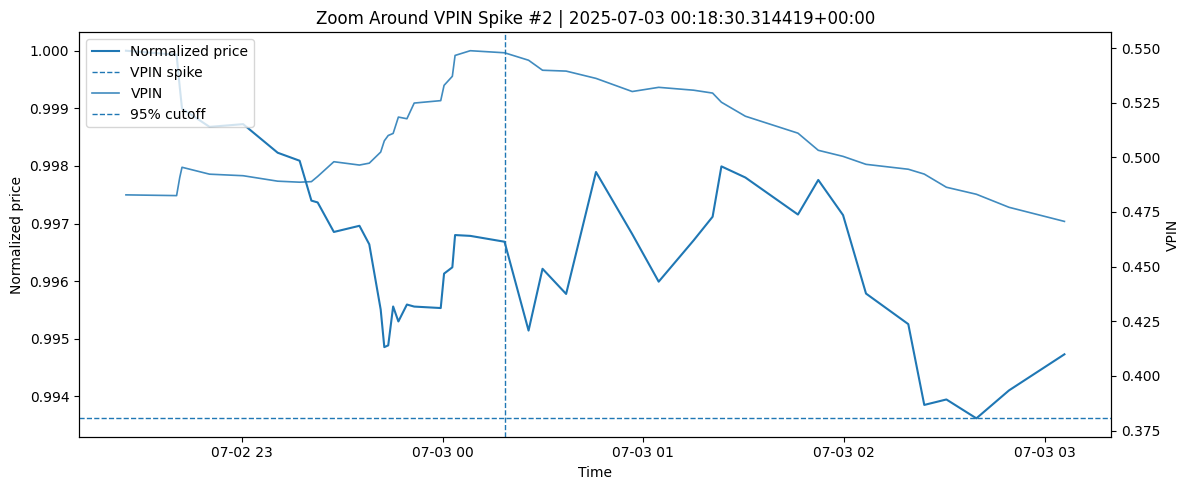

saved: outputs\figures\publication\fig7_spike_window_2_V50_n100.png


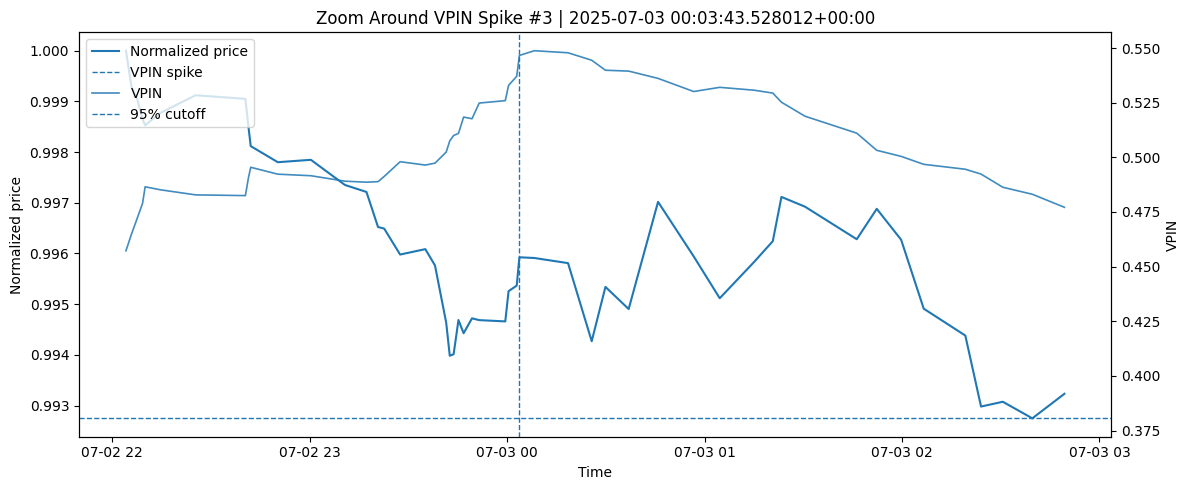

saved: outputs\figures\publication\fig7_spike_window_3_V50_n100.png


In [15]:
def plot_top_spike_windows(vpin_df, n_windows=3, before_min=120, after_min=180):
    x = vpin_df.dropna(subset=['vpin']).copy()
    top_spikes = x.sort_values('vpin', ascending=False).head(n_windows)
    for k, (_, row) in enumerate(top_spikes.iterrows(), start=1):
        t0 = row['end_time']; lo = t0 - pd.Timedelta(minutes=before_min); hi = t0 + pd.Timedelta(minutes=after_min)
        w = x[(x['end_time'] >= lo) & (x['end_time'] <= hi)].copy()
        if len(w) == 0: continue
        w['price_norm'] = w['end_price'] / w['end_price'].iloc[0]
        fig, ax1 = plt.subplots(figsize=(12, 5))
        ax1.plot(w['end_time'], w['price_norm'], linewidth=1.5, label='Normalized price')
        ax1.axvline(t0, linestyle='--', linewidth=1.0, label='VPIN spike')
        ax1.set_ylabel('Normalized price'); ax1.set_xlabel('Time')
        ax2 = ax1.twinx(); ax2.plot(w['end_time'], w['vpin'], linewidth=1.2, alpha=0.85, label='VPIN')
        ax2.axhline(vpin_cutoff, linestyle='--', linewidth=1.0, label='95% cutoff'); ax2.set_ylabel('VPIN')
        lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
        plt.title(f'Zoom Around VPIN Spike #{k} | {t0}'); fig.tight_layout()
        out = REPORT_FIG_DIR / f'fig7_spike_window_{k}_V{int(BEST_V)}_n{BEST_N}.png'
        plt.savefig(out, dpi=180); plt.show(); print('saved:', out)
plot_top_spike_windows(vpin_df, n_windows=3)
